# Imports

In [5]:
import os
# I need this to run torch on my computer, remove it according to your GPU ~Omar
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

## Verify Torch is working

# Data Preparation

## Loading the Dataset

In [7]:
notebook_folderPath = Path().absolute()
print(notebook_folderPath.parent)

/home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces


In [8]:
from datasets import Dataset, DatasetDict, load_from_disk
from dataset_preparer import load_and_split_dataset, LazyLoadingImageDataset

dataset_object_filepath = notebook_folderPath / "input"
dataset_source_folderpath = notebook_folderPath.parent.parent / "Datasets - Unsplit" / "X-Ray Region Classification"
labels = None #Loads all when set to None

if (dataset_object_filepath / "dataset_dict.json").is_file():
    print("Dataset Already Loaded, skipping split")
    dataset = load_from_disk(str(dataset_object_filepath))
else:
    dataset = load_and_split_dataset(labels, dataset_source_folderpath)
    print("Saving Dataset Object for Future Use...")
    dataset.save_to_disk(str(dataset_object_filepath))


dataset

Loading dataset from source at /home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Datasets - Unsplit/X-Ray Region Classification...
Minimum count in labels is 1560 for label Humerus, downsampling other classes to this count...


Flattening the indices: 100%|██████████| 156/156 [00:00<00:00, 172006.16 examples/s]


Saving Dataset Object for Future Use...


Saving the dataset (1/1 shards): 100%|██████████| 1404/1404 [00:00<00:00, 393583.93 examples/s]


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 9828
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 2808
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1404
    })
})

In [9]:
dataset["train"] = LazyLoadingImageDataset(dataset["train"], size=(224, 224), padding=True)
dataset["validation"] = LazyLoadingImageDataset(dataset["validation"], size=(224, 224), padding=True)
dataset["test"] = LazyLoadingImageDataset(dataset["test"], size=(224, 224), padding=True)

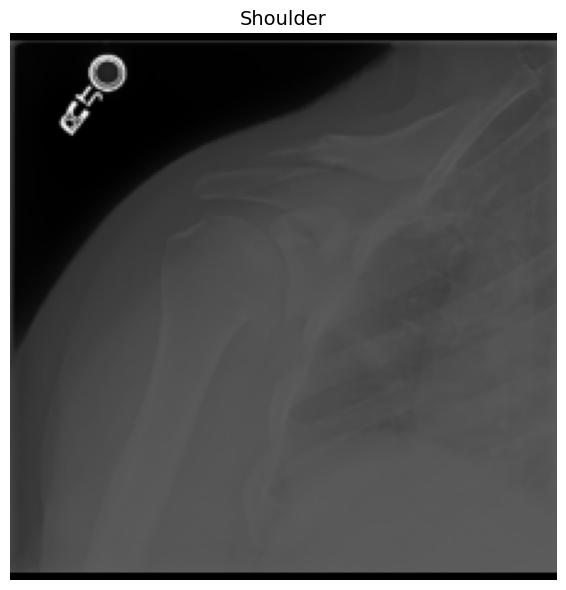

In [10]:
def plot_image_entry(entry):
    """
    Plot an image from a dataset entry with the label as title.
    
    Args:
        entry: Dictionary with 'image' and 'label' keys
    """
    image = entry["image"]
    label = entry["label"]
    
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap='gray')
    plt.title(label, fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_image_entry(dataset["train"][1355])